# 29 — Similarity CNN: first development experiment

Train one terrain encoder and a similarity head for **Earth ↔ Moon retrieval**. Terrain assessment continues to use physical measurements and explicit mission constraints; no difficulty prediction head is trained here.

The experiment uses notebook 28's pinned tensors and EDA-exposed development split. Atacama and Leibnitz remain development holdouts. Proposed validation/final reserves are not opened. Configuration lives in [similarity_experiment.json](similarity_experiment.json); training and inference are reusable modules [similarity_cnn.py](../../similarity_cnn.py) and [similarity_experiment.py](../../similarity_experiment.py).

**Question:** can learned spatial representations eventually improve independently judged analog relevance beyond the physical baseline? This run establishes the training/retrieval workflow and diagnostics. No independent relevance labels exist yet, so it cannot answer that quality question.

## Fixed first-experiment choices

- Three physical channels: patch-relative elevation, slope, local elevation SD. Inputs are 960 m / 32 × 32 cells and use notebook 28's training-only scaler.
- Encoder: three stride-2 convolutions with 16/32/64 channels, followed by 64 features. A separate similarity head produces a unit 64-dimensional vector. No per-patch amplitude rescaling or per-image normalization layers.
- Same-patch positives use independent 0/90/180/270-degree rotations, applied to all channels together. No resized crops, height scaling or artificial rock labels. Rotation invariance is a hypothesis for morphology-only search, not directional illumination or route planning.
- NT-Xent contrastive loss treats other nonoverlapping batch patches as negatives. Remove duplicate and context-overlapping patches from the negative pool. Distant patches can still be valid analogs: these remaining false negatives are a limitation to investigate.
- Four fixed runs: full-context / image-supported lunar views × region-balanced / count-weighted sampling. Each view has its own encoder experiment; within each experiment the same encoder handles Earth and Moon. This compares support policies, not separate Earth/Moon models. Each run has seed 29, 10 epochs, 32 batches/epoch and 128 draws/batch. Sampling uses replacement; audit actual regional exposure.
- Final epoch is used for every run, without selecting checkpoints from holdout results. One seed and a short training budget are exploratory. Exact reproduction across different hardware/software is not guaranteed.
- Inference averages embeddings across four rotations and normalizes the result. Model files store state dictionaries; preprocessing and dataset references are saved alongside them.

Method background: [SimCLR](https://proceedings.mlr.press/v119/chen20j.html). This is a small terrain-specific contrastive experiment, not a reproduction of its image benchmark.

## Environment and execution

Use the project Python 3.12 environment. Install processing dependencies first, then the pinned CUDA modeling dependencies:

```powershell
uv pip install --python .venv/Scripts/python.exe -r notebooks/requirements-modeling.txt
```

The default is `cuda:0`. CPU use requires an explicit configuration change. The terminal equivalent is `python notebooks/similarity_experiment.py`. Each execution creates a fresh ignored run under `data/processed/terrain_similarity_cnn/`. Raw data, previous runs and final reserves remain unchanged.

In [7]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from inspection import file_hash
from similarity_experiment import run_experiments

CONFIG = ROOT / "notebooks/modeling/terrain_similarity/similarity_experiment.json"
config = json.loads(CONFIG.read_text(encoding="utf-8"))
display(config)

{'dataset_run': 'data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac',
 'views': ['full_context', 'image_supported'],
 'sampling_modes': ['region_balanced', 'count_weighted'],
 'seed': 29,
 'epochs': 10,
 'steps_per_epoch': 32,
 'batch_size': 128,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'temperature': 0.2,
 'queries_per_region': 32,
 'top_k': 5,
 'device': 'cuda:0',
 'selection_rule': 'Use the final epoch for every experiment; no tuning or model selection on holdout results',
 'quality_gate': 'Exploratory only: independent relevance judgments are missing; no model promotion or suitability claims'}

In [8]:
OUT = run_experiments(ROOT, CONFIG)
print("Complete:", OUT.relative_to(ROOT))
FIGURES = ROOT / "reports/terrain-similarity-cnn" / OUT.name
FIGURES.mkdir(parents=True, exist_ok=True)

region_balanced 1 loss 4.3425426334142685
region_balanced 2 loss 3.2869484201073647
region_balanced 3 loss 2.6187380850315094
region_balanced 4 loss 2.329697757959366
region_balanced 5 loss 2.193375527858734
region_balanced 6 loss 2.060201521962881
region_balanced 7 loss 2.0047256387770176
region_balanced 8 loss 1.917143814265728
region_balanced 9 loss 1.8788584098219872
region_balanced 10 loss 1.8311227411031723
count_weighted 1 loss 4.278215058147907
count_weighted 2 loss 3.2230583280324936
count_weighted 3 loss 2.6383370608091354
count_weighted 4 loss 2.371138520538807
count_weighted 5 loss 2.2331510931253433
count_weighted 6 loss 2.1092090755701065
count_weighted 7 loss 2.0324831046164036
count_weighted 8 loss 1.9224308878183365
count_weighted 9 loss 1.9366247579455376
count_weighted 10 loss 1.870236597955227
region_balanced 1 loss 4.381604261696339
region_balanced 2 loss 3.542267866432667
region_balanced 3 loss 3.0077293440699577
region_balanced 4 loss 2.621331125497818
region_bal

## Training and representation diagnostics

Falling contrastive loss shows progress on the augmentation task, not analog relevance. Inspect embedding spread/effective rank for collapse. A training-body-centroid classifier evaluated on development holdouts checks how easily Earth and Moon are distinguished. High body separation could reflect geology, source processing, or both; it is a warning to investigate rather than a diagnosis.

Region-balanced sampling can repeatedly expose a small site such as Lanzarote. The saved training-exposure tables report unique patches and draw counts; all holdout draws must be zero.

,,size,sum,max
region,fold,,,
A3CLR22_10_Leibnitz_Beta_Plateau,holdout,225,0,0
A3CLR22_11_Malapert_Massif,train,400,3963,18
A3CLR22_12_deGerlache_Kocher_Massif,train,361,4175,22
A3CLR22_2_Haworth,train,841,4089,13
A3CLR22_3_Faustini_Rim_A,train,361,4133,23
A3CLR22_4_deGerlache_Rim_2,train,361,4060,25
A3CLR22_5_Connecting_Ridge_Extension,train,361,4047,22
atacama_san_pedro,holdout,3078,0,0
death_valley,train,674,4071,16


,,size,sum,max
region,fold,,,
A3CLR22_10_Leibnitz_Beta_Plateau,holdout,225,0,0
A3CLR22_11_Malapert_Massif,train,400,3104,18
A3CLR22_12_deGerlache_Kocher_Massif,train,361,2817,17
A3CLR22_2_Haworth,train,841,6520,18
A3CLR22_3_Faustini_Rim_A,train,361,2782,19
A3CLR22_4_deGerlache_Rim_2,train,361,2730,16
A3CLR22_5_Connecting_Ridge_Extension,train,361,2778,17
atacama_san_pedro,holdout,3078,0,0
death_valley,train,674,5180,18


,,size,sum,max
region,fold,,,
A3CLR22_10_Leibnitz_Beta_Plateau,holdout,68,0,0
A3CLR22_11_Malapert_Massif,train,229,3963,30
A3CLR22_12_deGerlache_Kocher_Massif,train,216,4175,31
A3CLR22_2_Haworth,train,129,4089,44
A3CLR22_3_Faustini_Rim_A,train,71,4133,79
A3CLR22_4_deGerlache_Rim_2,train,134,4060,45
A3CLR22_5_Connecting_Ridge_Extension,train,167,4047,40
atacama_san_pedro,holdout,3078,0,0
death_valley,train,674,4071,16


,,size,sum,max
region,fold,,,
A3CLR22_10_Leibnitz_Beta_Plateau,holdout,68,0,0
A3CLR22_11_Malapert_Massif,train,229,2671,20
A3CLR22_12_deGerlache_Kocher_Massif,train,216,2483,26
A3CLR22_2_Haworth,train,129,1445,21
A3CLR22_3_Faustini_Rim_A,train,71,785,23
A3CLR22_4_deGerlache_Rim_2,train,134,1539,20
A3CLR22_5_Connecting_Ridge_Extension,train,167,1909,21
atacama_san_pedro,holdout,3078,0,0
death_valley,train,674,7747,25


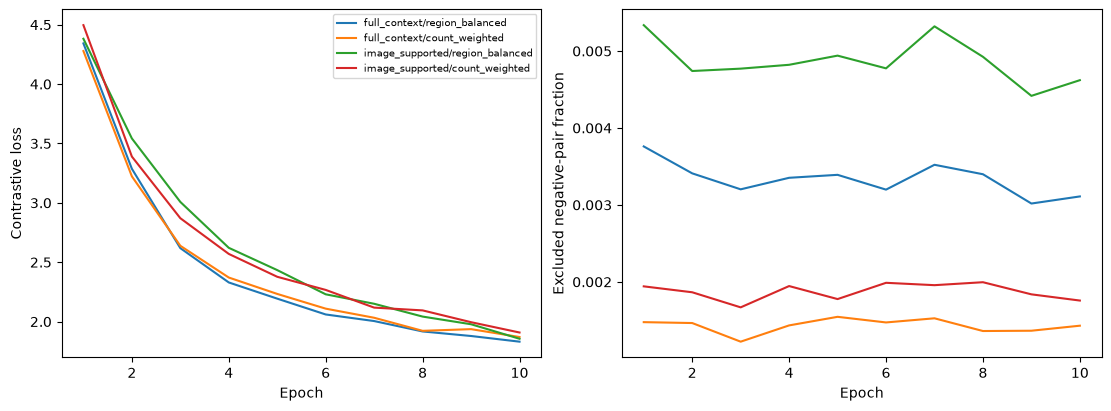

,view,sampling,method,mean_coordinate_sd,effective_rank,body_balanced_accuracy
0,full_context,region_balanced,random_encoder,0.003604,2.161764,0.687089
1,full_context,region_balanced,cnn,0.122226,19.664700,0.653788
2,full_context,count_weighted,random_encoder,0.003604,2.161764,0.687089
3,full_context,count_weighted,cnn,0.122366,20.844770,0.771313
4,image_supported,region_balanced,random_encoder,0.002939,2.435762,0.884474
5,image_supported,region_balanced,cnn,0.119860,15.677568,0.760669
6,image_supported,count_weighted,random_encoder,0.002939,2.435762,0.884474
7,image_supported,count_weighted,cnn,0.120664,20.285049,0.830218


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
diagnostic_rows = []
for view in config["views"]:
    for mode in config["sampling_modes"]:
        folder = OUT / view / mode
        history = pd.read_csv(folder / "training_history.csv")
        label = f"{view}/{mode}"
        axes[0].plot(history["epoch"], history["loss"], label=label)
        axes[1].plot(history["epoch"], history["excluded_negative_fraction"], label=label)
        diagnostics = json.loads((folder / "embedding_diagnostics.json").read_text())
        for method, values in diagnostics.items():
            diagnostic_rows.append({"view": view, "sampling": mode, "method": method,
                                    "mean_coordinate_sd": values["mean_coordinate_sd"],
                                    "effective_rank": values["effective_rank"],
                                    "body_balanced_accuracy": values["heldout_body_balanced_accuracy"]})
        exposure = pd.read_csv(folder / "training_exposure.csv")
        assert exposure.loc[exposure["fold"] == "holdout", "training_draws"].sum() == 0
        display(exposure.groupby(["region", "fold"])["training_draws"].agg(["size", "sum", "max"]))
axes[0].set(xlabel="Epoch", ylabel="Contrastive loss")
axes[1].set(xlabel="Epoch", ylabel="Excluded negative-pair fraction")
axes[0].legend(fontsize=7)
fig.savefig(FIGURES / "training.png", dpi=130)
plt.show()
plt.close(fig)
display(pd.DataFrame(diagnostic_rows))

## Bidirectional retrieval controls

Use the same seeded sample of up to 32 query patches per region and the complete eligible candidate pool for each method. Compare held-out queries, held-out candidates and both held out in **both directions**. Views can retain different query locations; their aggregate differences include selection effects.

Compare physical descriptors, an untrained random encoder, and the trained CNN. Physical scores are lower-is-closer discrepancies; CNN scores are higher-is-closer cosine similarities. Do not compare their numeric scales. Top-k overlap measures disagreement with the baseline, not accuracy. Regional macro summaries give regions equal weight, but the few geographical groups still limit generalization.

In [10]:
for view in config["views"]:
    for mode in config["sampling_modes"]:
        print(view, mode)
        display(pd.read_csv(OUT / view / mode / "macro_comparison.csv"))

full_context region_balanced


,direction,case,method,top_k_region_count,overlap_with_physical_fraction
0,earth_to_moon,both_heldout,cnn,1.00000,0.106250
1,earth_to_moon,both_heldout,physical,1.00000,1.000000
2,earth_to_moon,both_heldout,random_encoder,1.00000,0.400000
3,earth_to_moon,heldout_candidates,cnn,1.00000,0.110937
4,earth_to_moon,heldout_candidates,physical,1.00000,1.000000
5,earth_to_moon,heldout_candidates,random_encoder,1.00000,0.471875
6,earth_to_moon,heldout_queries,cnn,2.87500,0.043750
7,earth_to_moon,heldout_queries,physical,2.53125,1.000000
8,earth_to_moon,heldout_queries,random_encoder,2.68750,0.093750
9,moon_to_earth,both_heldout,cnn,1.00000,0.087500


full_context count_weighted


,direction,case,method,top_k_region_count,overlap_with_physical_fraction
0,earth_to_moon,both_heldout,cnn,1.00000,0.087500
1,earth_to_moon,both_heldout,physical,1.00000,1.000000
2,earth_to_moon,both_heldout,random_encoder,1.00000,0.400000
3,earth_to_moon,heldout_candidates,cnn,1.00000,0.193750
4,earth_to_moon,heldout_candidates,physical,1.00000,1.000000
5,earth_to_moon,heldout_candidates,random_encoder,1.00000,0.471875
6,earth_to_moon,heldout_queries,cnn,3.21875,0.012500
7,earth_to_moon,heldout_queries,physical,2.53125,1.000000
8,earth_to_moon,heldout_queries,random_encoder,2.68750,0.093750
9,moon_to_earth,both_heldout,cnn,1.00000,0.062500


image_supported region_balanced


,direction,case,method,top_k_region_count,overlap_with_physical_fraction
0,earth_to_moon,both_heldout,cnn,1.00000,0.225000
1,earth_to_moon,both_heldout,physical,1.00000,1.000000
2,earth_to_moon,both_heldout,random_encoder,1.00000,0.643750
3,earth_to_moon,heldout_candidates,cnn,1.00000,0.121875
4,earth_to_moon,heldout_candidates,physical,1.00000,1.000000
5,earth_to_moon,heldout_candidates,random_encoder,1.00000,0.603125
6,earth_to_moon,heldout_queries,cnn,3.18750,0.087500
7,earth_to_moon,heldout_queries,physical,3.12500,1.000000
8,earth_to_moon,heldout_queries,random_encoder,3.03125,0.368750
9,moon_to_earth,both_heldout,cnn,1.00000,0.100000


image_supported count_weighted


,direction,case,method,top_k_region_count,overlap_with_physical_fraction
0,earth_to_moon,both_heldout,cnn,1.00000,0.268750
1,earth_to_moon,both_heldout,physical,1.00000,1.000000
2,earth_to_moon,both_heldout,random_encoder,1.00000,0.643750
3,earth_to_moon,heldout_candidates,cnn,1.00000,0.146875
4,earth_to_moon,heldout_candidates,physical,1.00000,1.000000
5,earth_to_moon,heldout_candidates,random_encoder,1.00000,0.603125
6,earth_to_moon,heldout_queries,cnn,2.87500,0.068750
7,earth_to_moon,heldout_queries,physical,3.12500,1.000000
8,earth_to_moon,heldout_queries,random_encoder,3.03125,0.368750
9,moon_to_earth,both_heldout,cnn,1.00000,0.068750


## Example queries: physical baseline versus CNN

Show one fixed query per direction from the both-held-out case, using the full-context / region-balanced experiment. The query and candidates share a physical elevation color scale within each row. The examples do not select a winning method; judge terrain arrangements separately from rank and source quality.

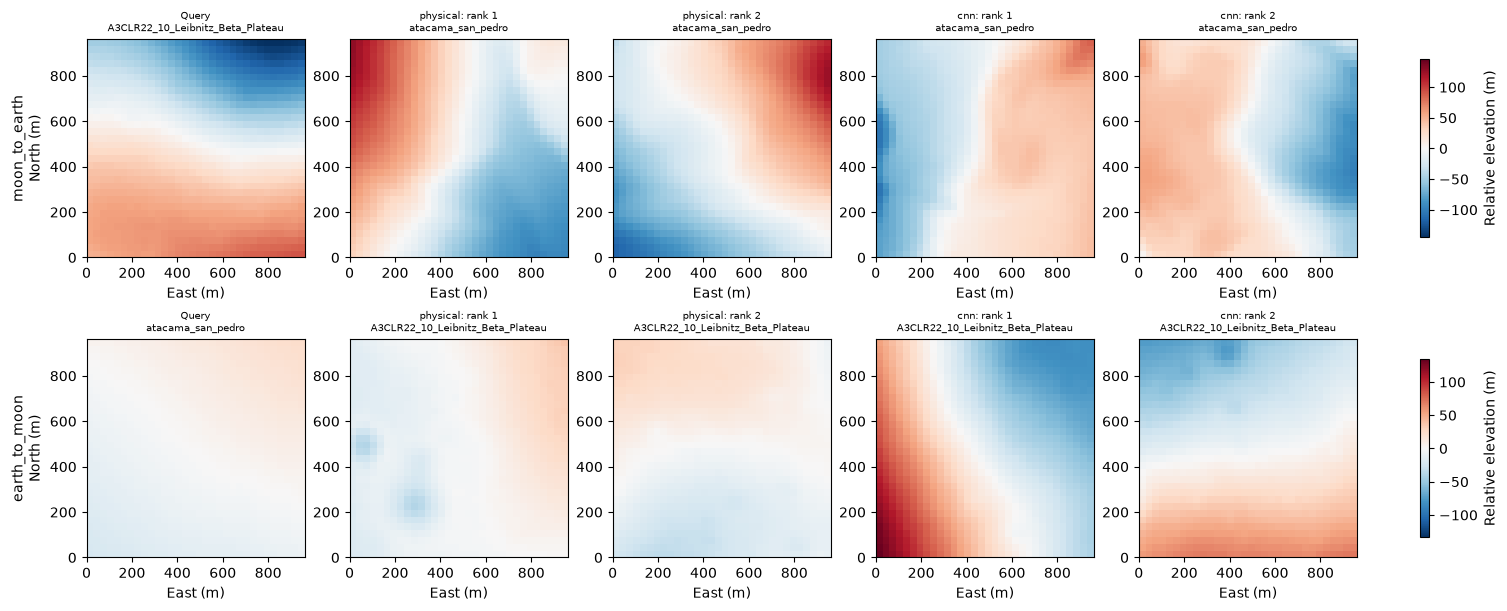

In [11]:
dataset = ROOT / config["dataset_run"]
patches = pd.read_csv(dataset / "patches.csv").set_index("patch_id")
rankings = pd.read_csv(OUT / "full_context/region_balanced/retrieval.csv")
fig, axes = plt.subplots(2, 5, figsize=(15, 6), constrained_layout=True)
for row, direction in enumerate(["moon_to_earth", "earth_to_moon"]):
    part = rankings.loc[(rankings["direction"] == direction) & (rankings["case"] == "both_heldout")]
    query_id = min(part["query_id"])
    part = part.loc[part["query_id"] == query_id]
    ids = [query_id]
    titles = ["Query"]
    for method in ["physical", "cnn"]:
        ids.extend(part.loc[part["method"] == method].sort_values("rank")["candidate_id"].head(2).tolist())
        titles.extend([f"{method}: rank 1", f"{method}: rank 2"])
    images = []
    for patch_id in ids:
        patch = patches.loc[patch_id]
        with np.load(dataset / patch["shard"], allow_pickle=False) as stored:
            images.append(stored["physical"][int(patch["tensor_index"]), 0])
    limit = max(float(np.max(np.abs(values))) for values in images) or 1.
    for column, (patch_id, title, values) in enumerate(zip(ids, titles, images, strict=True)):
        im = axes[row, column].imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, extent=(0, 960, 0, 960))
        axes[row, column].set_title(title + "\n" + patches.loc[patch_id, "region"], fontsize=7)
        axes[row, column].set_xlabel("East (m)")
    axes[row, 0].set_ylabel(direction + "\nNorth (m)")
    fig.colorbar(im, ax=list(axes[row]), label="Relative elevation (m)", shrink=.75)
fig.savefig(FIGURES / "retrieval_examples.png", dpi=130)
plt.show()
plt.close(fig)

## Relevance review and the next decision

The pooled worksheet combines the physical baseline, random encoder, both sampling modes and additional random candidates for two of the evaluated queries per region, per direction and applicable case. Candidate pairs are deduplicated and shuffled without method labels or scores. All relevance fields remain blank; pooled retrieval is still not an exhaustive or unbiased relevance benchmark.

Agree on an independent morphology rubric and let reviewers label relevant / partly relevant / irrelevant / uncertain with reasons. Allow queries with no relevant candidates. Obtain additional relevant examples outside this pool before claiming recall. Freeze metrics and no-match rules before using judgments to choose a model. Do not select the best experiment from physical-baseline agreement or the gallery.

Next work follows the evidence: inspect source/body shortcuts and severe morphology mismatches, review relevance, and only then consider augmentation changes, more seeds, support-policy changes or a supervised similarity objective. The proposed assessment head still needs suitable terrain/mobility labels.

In [12]:
review = pd.read_csv(OUT / "pooled_review_unlabeled.csv", keep_default_na=False)
assert (review["relevance"] == "").all()
display(review.head(10))
print(len(review), "unlabeled pooled pairs")
figure_provenance = {"source_run": str(OUT.relative_to(ROOT)),
                     "source_provenance_sha256": file_hash(OUT / "provenance.json"),
                     "notebook_sha256": file_hash(ROOT / "notebooks/modeling/terrain_similarity/29_similarity_cnn_experiment.ipynb"),
                     "outputs": {p.name: file_hash(p) for p in FIGURES.glob("*.png")}}
(FIGURES / "provenance.json").write_text(json.dumps(figure_provenance, indent=2), encoding="utf-8")
print("Models and diagnostics:", OUT)
print("Figures:", FIGURES)
print("Independent relevance remains unvalidated; no model promoted.")

,direction,case,query_id,candidate_id,view,relevance,reviewer,reason
0,moon_to_earth,heldout_candidates,A3CLR22_3_Faustini_Rim_A:image_supported:464:6...,atacama_san_pedro:natural_screen:1904:2704:960,image_supported,,,
1,earth_to_moon,heldout_candidates,lanzarote:natural_screen:880:688:960,A3CLR22_10_Leibnitz_Beta_Plateau:image_support...,image_supported,,,
2,moon_to_earth,heldout_candidates,A3CLR22_3_Faustini_Rim_A:full_context:176:48:960,atacama_san_pedro:natural_screen:656:592:960,full_context,,,
3,moon_to_earth,heldout_candidates,A3CLR22_4_deGerlache_Rim_2:image_supported:112...,atacama_san_pedro:natural_screen:848:2480:960,image_supported,,,
4,earth_to_moon,heldout_candidates,death_valley:natural_screen:1232:816:960,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,full_context,,,
5,earth_to_moon,heldout_candidates,lanzarote:natural_screen:880:688:960,A3CLR22_10_Leibnitz_Beta_Plateau:image_support...,image_supported,,,
6,moon_to_earth,heldout_candidates,A3CLR22_12_deGerlache_Kocher_Massif:full_conte...,atacama_san_pedro:natural_screen:880:1424:960,full_context,,,
7,moon_to_earth,heldout_candidates,A3CLR22_3_Faustini_Rim_A:image_supported:464:6...,atacama_san_pedro:natural_screen:592:2416:960,image_supported,,,
8,earth_to_moon,heldout_candidates,northern_arizona:natural_screen:368:3664:960,A3CLR22_10_Leibnitz_Beta_Plateau:image_support...,image_supported,,,
9,moon_to_earth,heldout_candidates,A3CLR22_5_Connecting_Ridge_Extension:full_cont...,atacama_san_pedro:natural_screen:1712:368:960,full_context,,,


984 unlabeled pooled pairs
Models and diagnostics: .\data\processed\terrain_similarity_cnn\20261102T143633484633Z_34dfee
Figures: .\reports\terrain-similarity-cnn\20261102T143633484633Z_34dfee
Independent relevance remains unvalidated; no model promoted.
